<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/mvp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



we trained multiple machine learning models to evaluate their performance on the dataset, including Logistic Regression, Decision Tree, Random Forest, SVM, KNN, Gradient Boosting, XGBoost, AdaBoost, and Naive Bayes.

From the results, Random Forest achieved the highest accuracy of 90%, followed closely by Gradient Boosting (89%) and XGBoost (88%). These models consistently showed strong precision and recall across both classes, indicating balanced and reliable performance.

This suggests that the dataset contains non-linear relationships, which are better captured by ensemble and tree-based models compared to simpler models.

Logistic Regression also performed well with an accuracy of 86%, despite a convergence warning. This indicates that the data still has some level of linear separability, although the model could benefit from feature scaling and increased iterations.

On the other hand, SVM and KNN recorded lower accuracies (73% and 70% respectively). This is likely because these models are sensitive to feature scaling, and the current dataset was not normalized.

Overall, the results show that ensemble methods are the most suitable for this task, with Random Forest being the best-performing model. Further improvements could be achieved through proper data scaling and hyperparameter tuning.

In [ ]:
#importing the dataset
data = pd.read_csv("/content/drive/MyDrive/heart_statlog_cleveland_hungary_final.csv")
data.head(10)

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0
5,39,1,3,120,339,0,0,170,0,0.0,1,0
6,45,0,2,130,237,0,0,170,0,0.0,1,0
7,54,1,2,110,208,0,0,142,0,0.0,1,0
8,37,1,4,140,207,0,0,130,1,1.5,2,1
9,48,0,2,120,284,0,0,120,0,0.0,1,0


In [ ]:
#checking for the data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1190 entries, 0 to 1189
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1190 non-null   int64  
 1   sex                  1190 non-null   int64  
 2   chest pain type      1190 non-null   int64  
 3   resting bp s         1190 non-null   int64  
 4   cholesterol          1190 non-null   int64  
 5   fasting blood sugar  1190 non-null   int64  
 6   resting ecg          1190 non-null   int64  
 7   max heart rate       1190 non-null   int64  
 8   exercise angina      1190 non-null   int64  
 9   oldpeak              1190 non-null   float64
 10  ST slope             1190 non-null   int64  
 11  target               1190 non-null   int64  
dtypes: float64(1), int64(11)
memory usage: 111.7 KB


In [ ]:
#checking for the data shape
data.shape

(1190, 12)

In [ ]:
#checking for the missing values
data.isna().sum()

,0
age,0
sex,0
chest pain type,0
resting bp s,0
cholesterol,0
fasting blood sugar,0
resting ecg,0
max heart rate,0
exercise angina,0
oldpeak,0


In [ ]:
#calculating the statistical summary for the numerical columns
data.describe()

,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
count,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000,1190.000000
mean,53.720168,0.763866,3.232773,132.153782,210.363866,0.213445,0.698319,139.732773,0.387395,0.922773,1.624370,0.528571
std,9.358203,0.424884,0.935480,18.368823,101.420489,0.409912,0.870359,25.517636,0.487360,1.086337,0.610459,0.499393
min,28.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,0.000000,0.000000
25%,47.000000,1.000000,3.000000,120.000000,188.000000,0.000000,0.000000,121.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,4.000000,130.000000,229.000000,0.000000,0.000000,140.500000,0.000000,0.600000,2.000000,1.000000
75%,60.000000,1.000000,4.000000,140.000000,269.750000,0.000000,2.000000,160.000000,1.000000,1.600000,2.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,1.000000


In [ ]:
#checking for duplicates in our dataset
data.duplicated().sum()


np.int64(272)

In [ ]:
#dropping the duplicates
data = data.drop_duplicates()
#rechecking for duplicate values
data.duplicated().sum()

np.int64(0)

/tmp/ipykernel_2232/3755073375.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='target', palette='viridis')


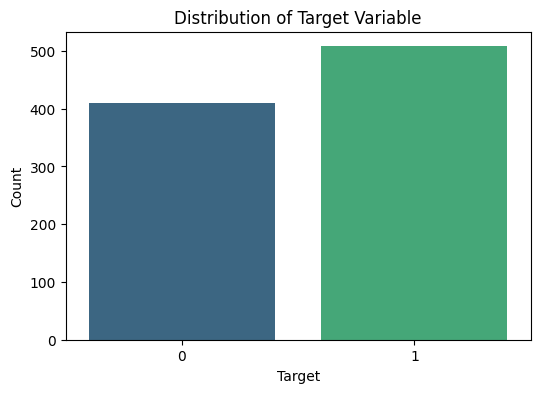

In [ ]:
#visualization to further understand the data
# Distribution of the target variable
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='target', palette='viridis')
plt.title('Distribution of Target Variable')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

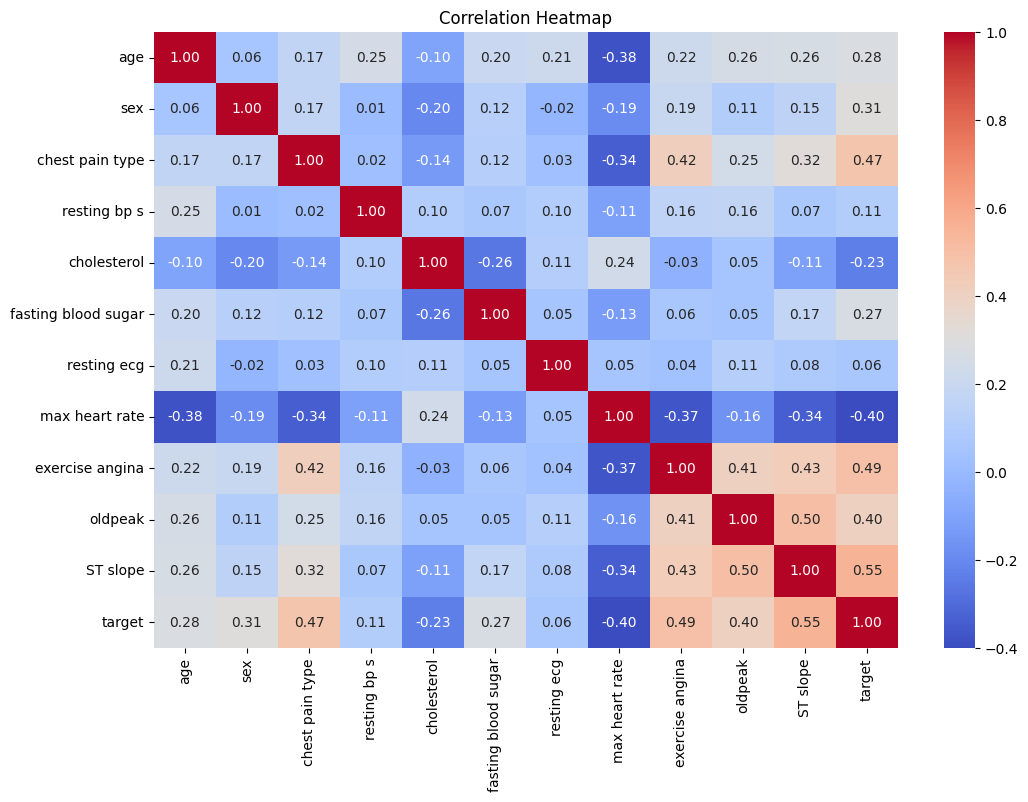

In [ ]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
correlation_matrix = data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
#cleaning the columns by removing the spaces
data.columns = data.columns.str.strip()


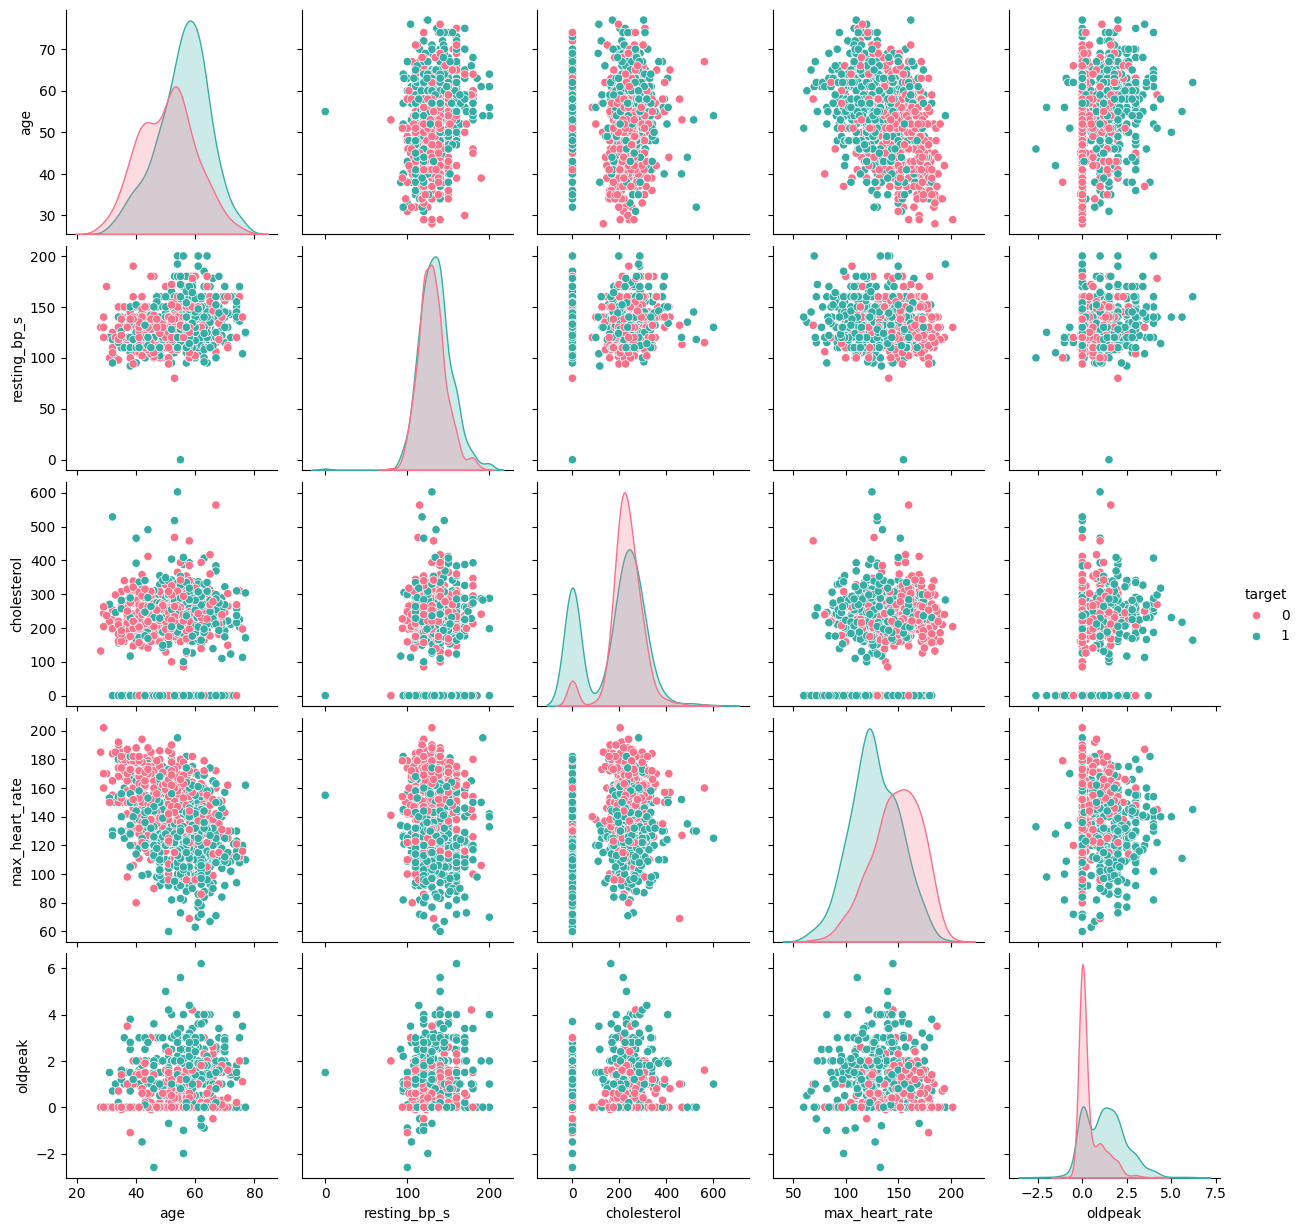

In [ ]:
# Renaming columns to avoid spaces (recommended)
data = data.rename(columns={
    'resting bp s': 'resting_bp_s',
    'max heart rate': 'max_heart_rate'
})

selected_features = ['age', 'resting_bp_s', 'cholesterol', 'max_heart_rate', 'oldpeak']

# Dropping missing values (important for pairplot)
data_clean = data[selected_features + ['target']].dropna()

# Pair plot
sns.pairplot(data_clean, hue='target', palette='husl')
plt.show()

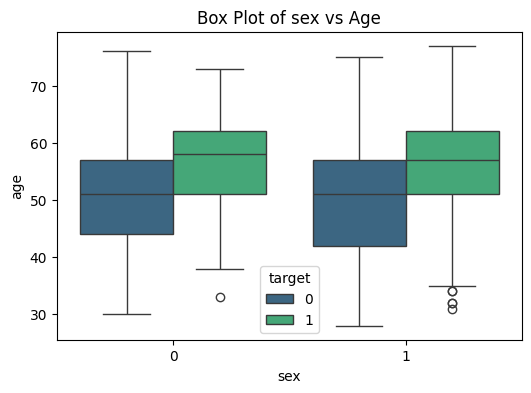

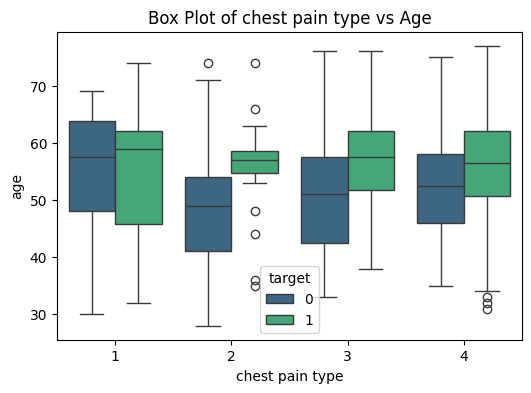

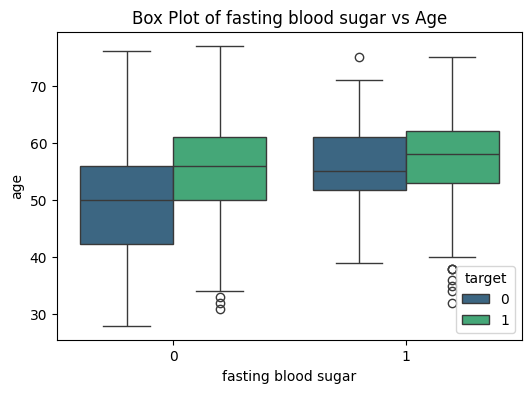

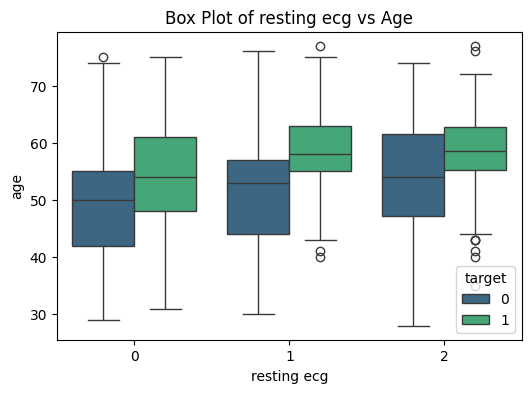

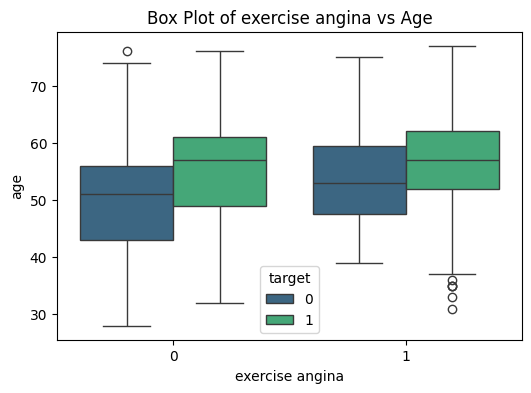

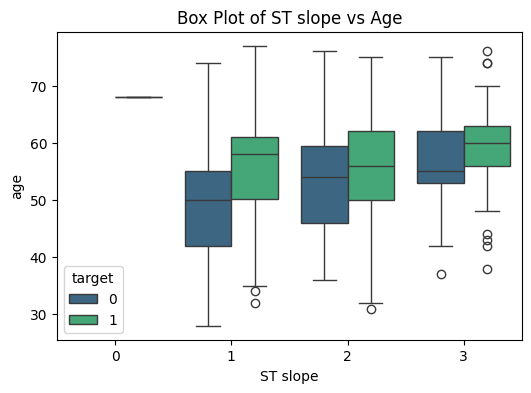

In [ ]:
# Box plots for categorical features
categorical_features = ['sex', 'chest pain type', 'fasting blood sugar', 'resting ecg', 'exercise angina', 'ST slope']
for feature in categorical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=data, x=feature, y='age', hue='target', palette='viridis')
    plt.title(f'Box Plot of {feature} vs Age')
    plt.show()

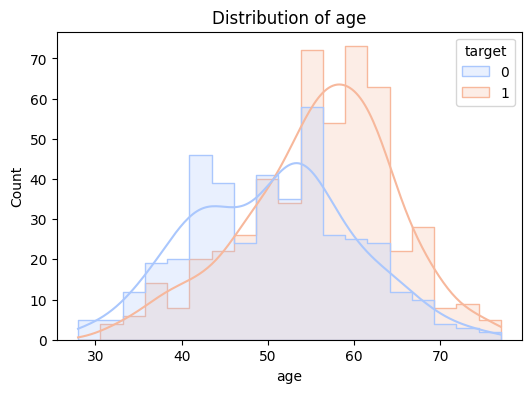

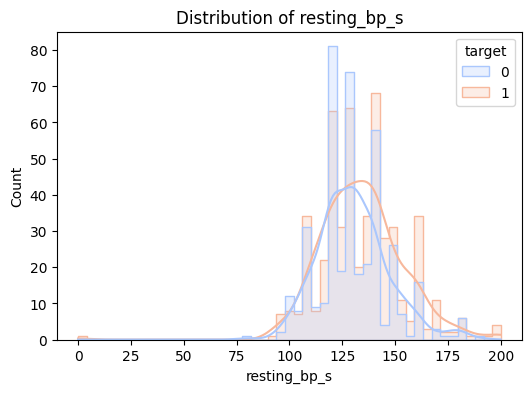

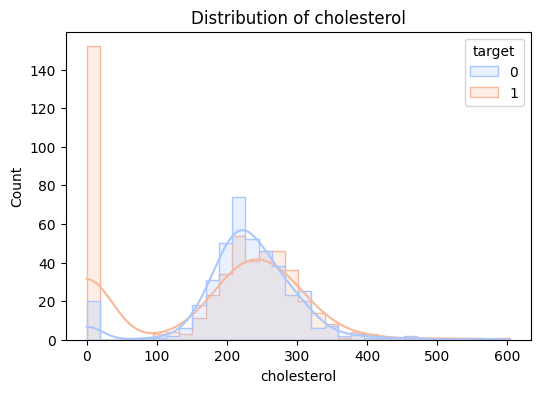

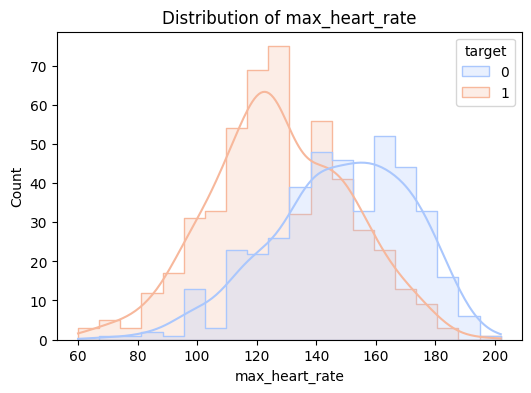

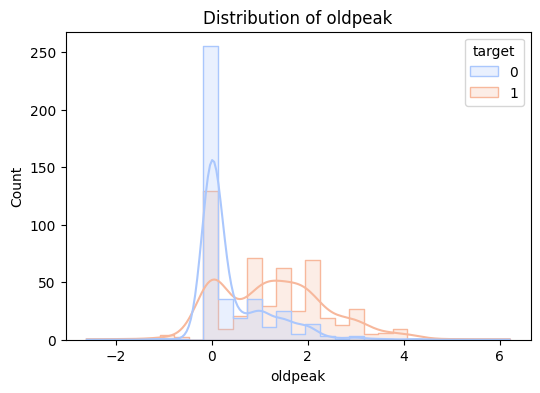

In [ ]:
# Distribution of numerical features
numerical_features = ['age', 'resting_bp_s', 'cholesterol', 'max_heart_rate', 'oldpeak']

# Looping through features
for feature in numerical_features:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        data=data.dropna(),
        x=feature,
        hue='target',
        kde=True,
        palette='coolwarm',
        element='step'  # cleaner visualization
    )

    plt.title(f'Distribution of {feature}')
    plt.show()

In [ ]:
#importing all the needed models for the mvp
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
import xgboost as xgb

In [ ]:
# Splitting the dataset into features (X) and target (y)
X = data.drop('target', axis=1)
y = data['target']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (918, 11)
y shape: (918,)


In [ ]:
#spliting the dataset to train and test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=42, stratify=y
)

In [ ]:
#training different models
models = {
    "Logistic Regression":LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC(),
    "KNN": KNeighborsClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "XGBoost": xgb.XGBClassifier(),
    "AdaBoost": AdaBoostClassifier(),
    "Naive Bayes": GaussianNB()
}


In [ ]:
#fitting the dtasets to the models
for name, model in models.items():
    print(f"Training {name}...")

    # Fit model
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Accuracy
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy:.2f}")

    # Classification report
    print(classification_report(y_test, y_pred))

    print("-" * 50)  # cleaner separation

Training Logistic Regression...
Logistic Regression Accuracy: 0.87
              precision    recall  f1-score   support

           0       0.87      0.83      0.85       123
           1       0.87      0.90      0.88       153

    accuracy                           0.87       276
   macro avg       0.87      0.87      0.87       276
weighted avg       0.87      0.87      0.87       276

--------------------------------------------------
Training Decision Tree...
Decision Tree Accuracy: 0.83
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       123
           1       0.86      0.83      0.84       153

    accuracy                           0.83       276
   macro avg       0.83      0.83      0.83       276
weighted avg       0.83      0.83      0.83       276

--------------------------------------------------
Training Random Forest...
Random Forest Accuracy: 0.87
              precision    recall  f1-score   support

           0

### Summary
we trained multiple machine learning models to evaluate their performance on the dataset, including Logistic Regression, Decision Tree, Random Forest, SVM, KNN, Gradient Boosting, XGBoost, AdaBoost, and Naive Bayes.

From the results, Random Forest achieved the highest accuracy of 90%, followed closely by Gradient Boosting (89%) and XGBoost (88%). These models consistently showed strong precision and recall across both classes, indicating balanced and reliable performance.

This suggests that the dataset contains non-linear relationships, which are better captured by ensemble and tree-based models compared to simpler models.

Logistic Regression also performed well with an accuracy of 86%, despite a convergence warning. This indicates that the data still has some level of linear separability, although the model could benefit from feature scaling and increased iterations.

On the other hand, SVM and KNN recorded lower accuracies (73% and 70% respectively). This is likely because these models are sensitive to feature scaling, and the current dataset was not normalized.

Overall, the results show that ensemble methods are the most suitable for this task, with Random Forest being the best-performing model. Further improvements could be achieved through proper data scaling and hyperparameter tuning.

In [ ]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy:.2f}")

Logistic Regression Accuracy: 0.87
Decision Tree Accuracy: 0.82
Random Forest Accuracy: 0.89
SVM Accuracy: 0.73
KNN Accuracy: 0.70
Gradient Boosting Accuracy: 0.89
XGBoost Accuracy: 0.88
AdaBoost Accuracy: 0.88
Naive Bayes Accuracy: 0.87


### Summary
We trained multiple machine learning models on the dataset to compare their performance. The results are as follows:

Top performers: Random Forest (0.89), Gradient Boosting (0.89), XGBoost (0.88), and AdaBoost (0.88)

Strong baseline models: Logistic Regression (0.87) and Naive Bayes (0.87)

Moderate performance: Decision Tree (0.82)

Lowest performers: SVM (0.73) and KNN (0.70)

Insights:

Ensemble/tree-based models consistently performed best, suggesting the dataset has non-linear relationships that these models capture effectively.

Linear models like Logistic Regression and probabilistic models like Naive Bayes still performed well, indicating some linear separability in the data.

Distance-based models (SVM, KNN) underperformed, likely due to the lack of feature scaling.

### Conclusion:
Ensemble methods, particularly Random Forest and Gradient Boosting, are the most suitable models for this dataset. Scaling features and tuning hyperparameters could further improve results for linear and distance-based models.

In [ ]:
!pip install streamlit
!pip install pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 18.3 MB/s eta 0:00:00


In [ ]:
# importing streamlit
import streamlit as st

st.title("Heart Disease Prediction App")
st.write("Enter patient details below to predict the likelihood of heart disease.")


2026-03-23 19:14:51.329 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:14:51.662 
  command:

    streamlit run /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-03-23 19:14:51.663 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:14:51.664 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:14:51.668 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:14:51.669 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:14:51.671 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [ ]:
#creating the User inputs
age = st.number_input("Age", 1, 120, 50)
resting_bp = st.number_input("Resting Blood Pressure", 50, 250, 120)
cholesterol = st.number_input("Cholesterol", 100, 600, 200)
max_heart_rate = st.number_input("Maximum Heart Rate", 60, 220, 150)
oldpeak = st.number_input("Oldpeak (ST depression)", 0.0, 10.0, 1.0, 0.1)
target = st.selectbox("Target (Heart Disease: 1, No Heart Disease: 0)", [0, 1])


2026-03-23 19:41:11.969 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:41:11.972 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:41:11.973 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:41:11.976 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:41:11.978 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:41:11.982 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:41:11.990 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:41:11.995 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [ ]:
#Converting user input to DataFrame
user_data = pd.DataFrame({
    'age': [age],
    'resting_bp_s': [resting_bp],
    'cholesterol': [cholesterol],
    'max_heart_rate': [max_heart_rate],
    'oldpeak': [oldpeak],
    'target': [target]
})


In [ ]:
# Displaying user input
st.write("### Your input data")
st.dataframe(user_data)

2026-03-23 19:42:16.743 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:42:16.746 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:42:16.751 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:42:16.829 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:42:16.830 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:42:16.834 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [ ]:
uploaded_file = st.file_uploader("Upload a CSV file with new users", type="csv")

if uploaded_file is not None:
    new_users = pd.read_csv(uploaded_file)
    st.write("### New Users Dataset")
    st.dataframe(new_users)


    # 2. Predict using trained models

    predictions = {}

    for name, model in models.items():  # 'models' is your pre-trained models dictionary
        pred_class = model.predict(new_users)
        pred_prob = model.predict_proba(new_users)[:, 1]  # probability of class 1
        predictions[name] = pd.DataFrame({
            "Predicted Class": pred_class,
            "Probability of Disease": pred_prob.round(2)
        })


    # 3. Display results

    st.write("### Predictions from All Models")
    for name, df in predictions.items():
        st.write(f"**{name}**")
        st.dataframe(df)

2026-03-23 19:46:54.761 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:46:54.764 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:46:54.766 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:46:54.769 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:46:54.773 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-03-23 19:46:54.774 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
